# <a id='toc1_'></a>[Ingeniería de características](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Ingeniería de características](#toc1_)    
  - [Extracción de la Marca (`brand`)](#toc1_1_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook se construyen y seleccionan las características que serán utilizadas posteriormente en los experimentos de clasificación. El objetivo es transformar la información disponible en el dataset en señales que puedan aportar información relevante para la predicción.

Se abordarán:

- selección de variables relevantes;
- creación de nuevas características a partir de `productDisplayName`;
- análisis y tratamiento conceptual de variables de alta cardinalidad;
- análisis de variables con distribución long-tail;
- definición de las variables objetivo para los experimentos posteriores.

En este notebook aplicamos la ingeniería de características sobre el dataset auditado (`styles_clean.csv`). 

**Objetivos:**
1. Extraer la marca comercial (`brand`) desde los nombres de los productos y consolidar marcas minoritarias.
2. Reducir la alta cardinalidad mediante la Regla de Pareto (90% acumulado) en `articleType` y `baseColour`.
3. Extraer señales léxicas y banderas de texto (atributos NLP simples) desde `productDisplayName`.
4. Exportar el conjunto de datos enriquecido (`styles_featured.csv`).

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from pathlib import Path

from fashion_mlops.utils.visualizations import analyze_high_cardinality, plot_heatmap_correlation, show_images
from fashion_mlops.features.build_features import clean_brand_column

## Carga del dataset

In [56]:
RANDOM_STATE = 42

DATA_PATH = Path("../data/interim/styles_clean.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset limpio cargado: {df.shape[0]} filas, {df.shape[1]} columnas.")

Dataset limpio cargado: 44419 filas, 10 columnas.


| Variable             | Papel         | Decisión                 |
| -------------------- | ------------- | ------------------------ |
| `id`                 | Identificador | No usar como feature     |
| `gender`             | Categoría     | Potencial target/feature |
| `masterCategory`     | Categoría     | Potencial target/feature |
| `subCategory`        | Categoría     | Potencial target/feature |
| `articleType`        | Categoría     | Potencial target/feature |
| `baseColour`         | Categoría     | Feature                  |
| `season`             | Categoría     | Potencial target/feature |
| `year`               | Numérica      | Feature                  |
| `usage`              | Categoría     | Potencial target/feature |
| `productDisplayName` | Texto         | Extraer nuevas features  |

## <a id='toc1_1_'></a>[Extracción de la Marca (`brand`)](#toc0_)

Extraemos el primer token del nombre comercial (`productDisplayName`).


In [6]:
df[["productDisplayName", "gender", "baseColour"]]

,productDisplayName,gender,baseColour
0,Turtle Check Men Navy Blue Shirt,Men,Navy Blue
1,Peter England Men Party Blue Jeans,Men,Blue
2,Titan Women Silver Watch,Women,Silver
3,Manchester United Men Solid Black Track Pants,Men,Black
4,Puma Men Grey T-shirt,Men,Grey
...,...,...,...
44414,Gas Men Caddy Casual Shoe,Men,White
44415,Lotto Men's Soccer Track Flip Flop,Men,Red
44416,Puma Men Graphic Stellar Blue Tshirt,Men,Blue
44417,Rasasi Women Blue Lady Perfume,Women,Blue


Observando la estructura de `productDisplayName`, nos damos cuenta que el nombre se construye aproximadamente como:
```py
[brand] [gender] [baseColour] [descripción]
```
Sin embargo, los datos contienen excepciones, erratas, variantes ortográficas y marcas que empiezan por palabras que también pueden ser colores o categorías. 

Considerando todas estas casuisticas llegamos a la función `clean_brand_column()` que combina tres niveles de reglas:
1. Reglas estructurales: cortar por palabras de género, público, color o descripción.
2. Reglas de normalización: corregir mayúsculas, prefijos, signos, espacios y pequeñas erratas.
3. Excepciones manuales: resolver marcas ambiguas o variantes que no pueden inferirse con seguridad automáticamente.



In [57]:
clean_brand_column(df, column="brand")

> Vamos a analizar como ha quedado la variable:

In [61]:
brand_counts = df["brand"].value_counts(dropna=False)
brand_counts.sort_values(ascending=False)

brand
NIKE                                        2364
PUMA                                        2186
ADIDAS                                      2080
UNITED COLORS OF BENETTON                   1401
LEE                                          814
                                            ... 
RTV_LOADTEST                                   1
KM CHANDBAGS WOMENCHERRY WRISTLET CLUTCH       1
VALLEY OF FLOWERS                              1
GIORGIO ARMANI                                 1
TEST DISPNAME                                  1
Name: count, Length: 388, dtype: int64

Tenemos 388 marcas, desde 2k aparciones hasta 1. Por lo que es una variable de alta cardinalidad. La tratamos como en el EDA:

Solo 144 categorías de 388 explican el 90.0% de los datos en 'brand'.


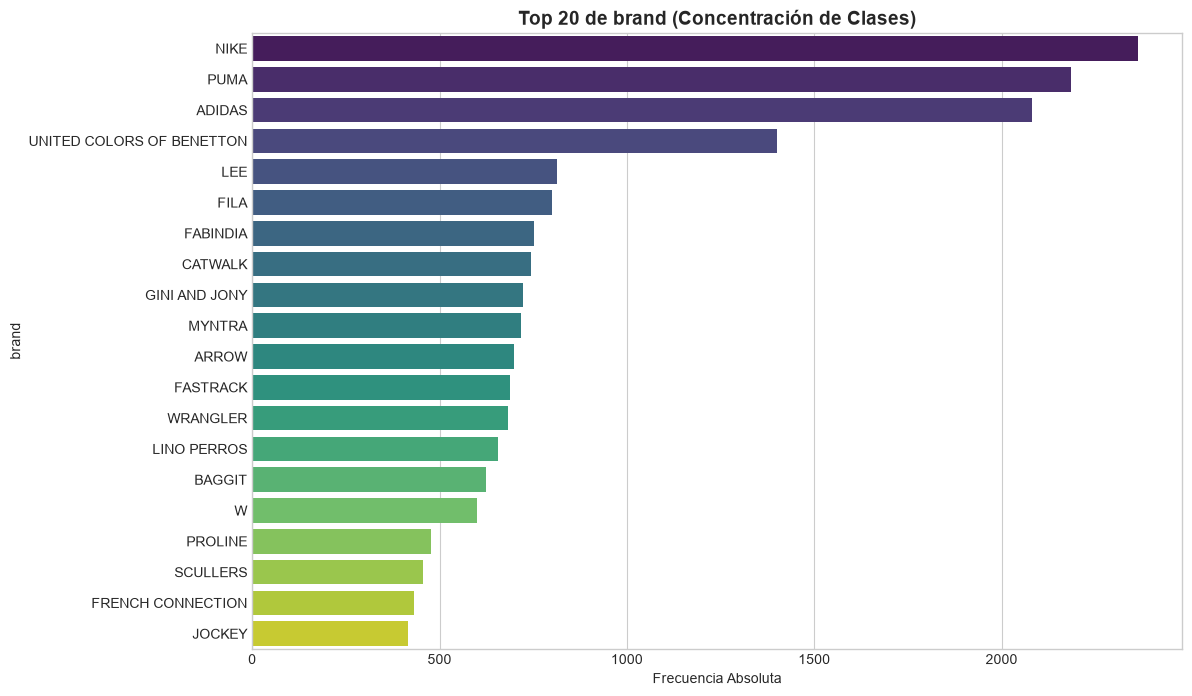

In [64]:
counts_br, per_br = analyze_high_cardinality(df, "brand")

In [62]:
brand_counts.describe()

count     388.000000
mean      114.481959
std       246.396095
min         1.000000
25%         9.000000
50%        30.000000
75%       109.500000
max      2364.000000
Name: count, dtype: float64

Vemos que una marca tiene, de media, ~114 productos y hay marcas que aparecen solo 1 vez. Por otro lado la mediana es 30 productos por marca, esta diferencia significa que la distribución está fuertemente sesgada hacia la derecha: unas pocas marcas tienen muchísimos productos y muchas marcas tienen pocos. Esto puede afectar negativamente el rendimiento de los modelos de machine learning, ya que las marcas con pocos registros pueden no proporcionar suficiente información para aprender patrones significativos.

In [66]:
thresholds = [1, 5, 10, 20, 50, 100]

for threshold in thresholds:
    n_brands = (brand_counts < threshold).sum()
    products = brand_counts[brand_counts < threshold].sum()

    print(
        f"< {threshold}: "
        f"{n_brands} marcas | "
        f"{products} productos"
    )

< 1: 0 marcas | 0 productos
< 5: 62 marcas | 154 productos
< 10: 104 marcas | 453 productos
< 20: 154 marcas | 1177 productos
< 50: 227 marcas | 3464 productos
< 100: 277 marcas | 7017 productos


Que valos aporta realmente `brand` a nuestro problema:

In [67]:
brand_target = pd.crosstab(
    df["brand"],
    df["masterCategory"],
    normalize="index"
)

brand_target.head()

masterCategory,Accessories,Apparel,Footwear,Free Items,Home,Personal Care,Sporting Goods
brand,,,,,,,
109F,0.000000,1.000000,0.0,0.0,0.0,0.000000,0.000000
18+,0.000000,0.000000,0.0,0.0,0.0,1.000000,0.000000
2GO ACTIVE GEAR USA,0.117647,0.882353,0.0,0.0,0.0,0.000000,0.000000
4711,0.000000,0.000000,0.0,0.0,0.0,1.000000,0.000000
ADIDAS,0.143750,0.443750,0.4,0.0,0.0,0.011058,0.001442


In [68]:
from scipy.stats import entropy

brand_entropy = (
    df.groupby("brand")["masterCategory"]
      .value_counts(normalize=True)
      .groupby(level=0)
      .apply(entropy)
      .sort_values()
)

brand_entropy.head(10)

brand
109F              0.0
NAUTILUS          0.0
MYNTRA            0.0
MUSIC             0.0
MUMBAI SLANG      0.0
MUMBAI INDIANS    0.0
MOTHER EARTH      0.0
MONT BLANC        0.0
MOD'ACC           0.0
MISS-T            0.0
Name: proportion, dtype: float64

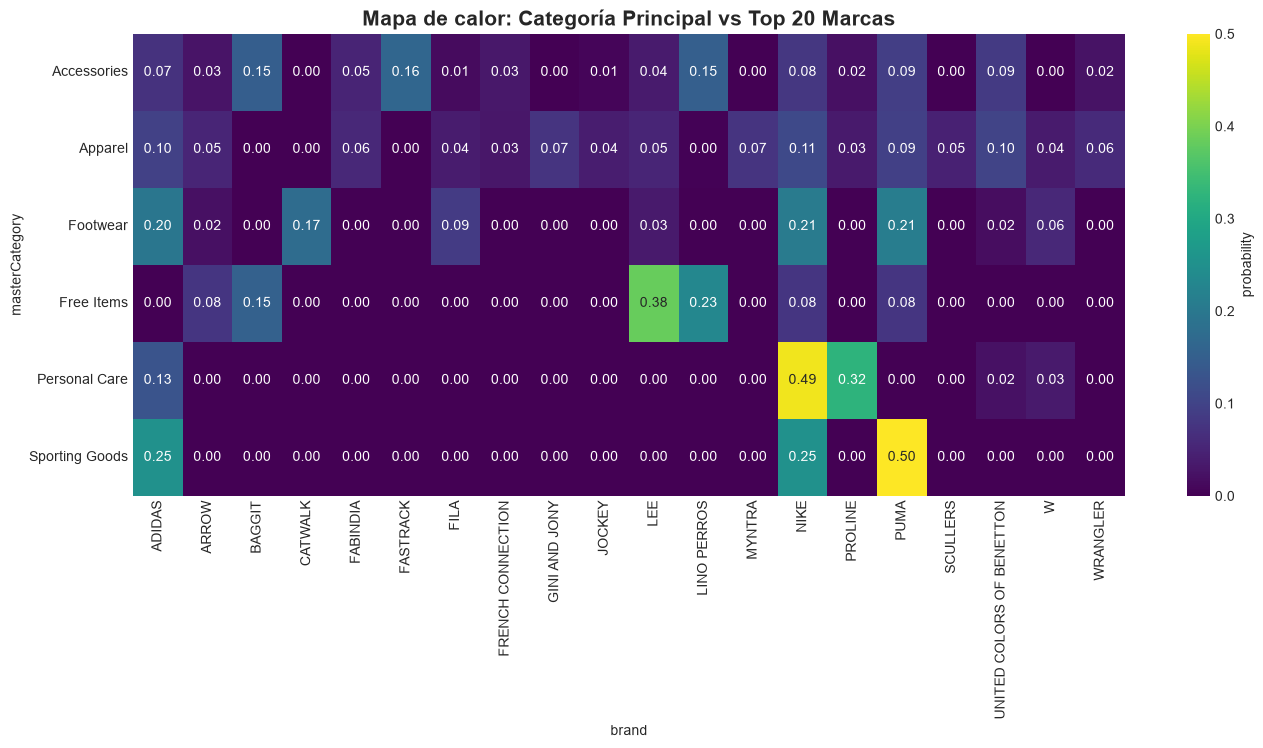

In [76]:
top_brands = df['brand'].value_counts().nlargest(20).index
df_filtered_brands = df[df['brand'].isin(top_brands)]

plot_heatmap_correlation(df_filtered_brands, "masterCategory", "brand", figsize=(16, 6), 
                        title='Mapa de calor: Categoría Principal vs Top 20 Marcas', normalize="index")

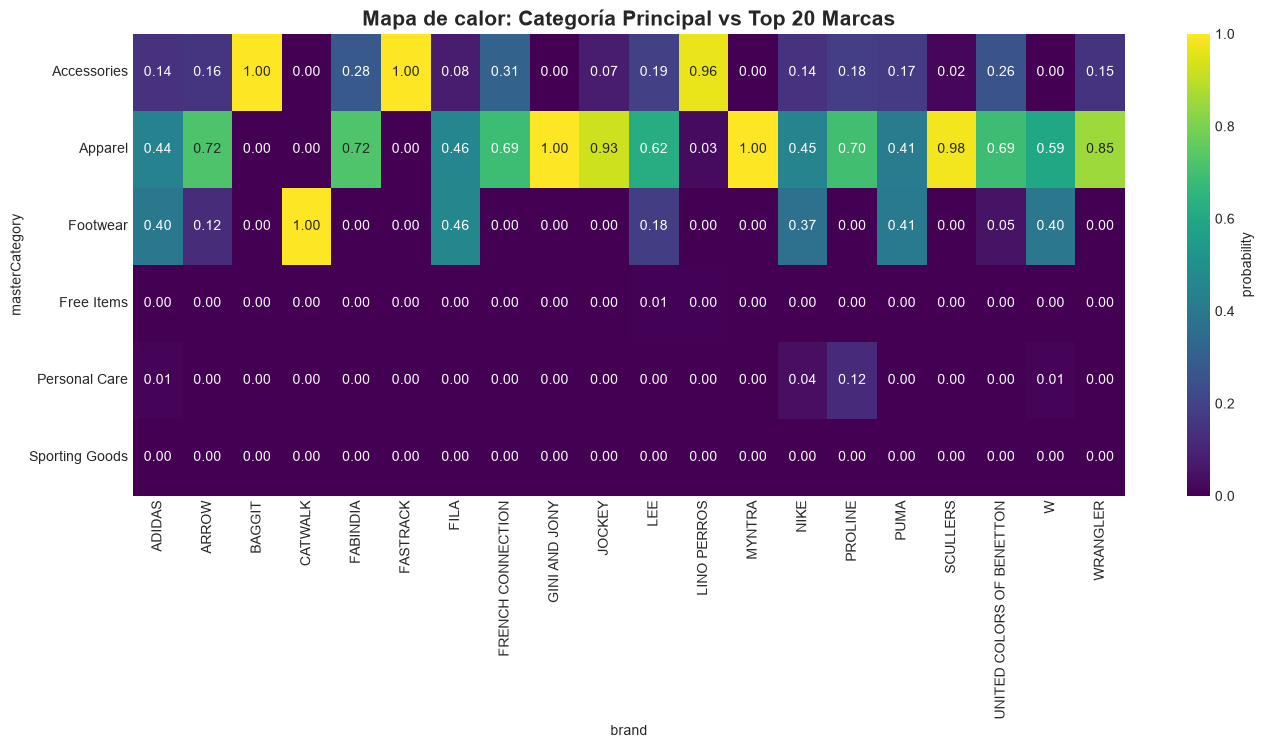

In [77]:
plot_heatmap_correlation(
    df_filtered_brands,
    "masterCategory",
    "brand",
    figsize=(16, 6),
    title="Mapa de calor: Categoría Principal vs Top 20 Marcas",
    normalize="columns"
)

El análisis de las 20 marcas con mayor frecuencia muestra una asociación notable entre brand y masterCategory. Algunas marcas presentan una elevada concentración en una categoría determinada, como CATWALK en Footwear, FASTRACK y BAGGIT en Accessories, o GINA AND JONY y MNTRA en Apparel. Otras marcas, como ADIDAS, NIKE y PUMA, presentan una distribución más heterogénea entre Apparel y Footwear. Estos resultados sugieren que brand puede contener información relevante para la predicción de masterCategory, aunque su capacidad predictiva no es uniforme entre marcas.